<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 11 · Hierarchies</p><p class="mh-facts"><span class="lvl lvl-advanced">Advanced</span></p><p class="mh-assumes">Assumes <a href="/blogs/many-series/forecasting_many_series.html">Forecasting many series at once</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Forecast every farm, every region and the total separately and the numbers will not add up. On a synthetic hierarchy of 12 farms in 2 regions, a region's forecast differed from the sum of its farms' forecasts by $8.4\text{ t/week}$ on average, about $12\%$ of the region's harvest. Reconciliation fixes this after forecasting. Every method is one matrix $G$ that turns all 15 base forecasts into 12 farm forecasts, which the summing matrix $S$ adds back up, so the result is coherent by construction. Bottom-up, top-down and middle-out each keep one level and discard the rest. OLS, WLS and MinT combine every level, weighting each base forecast by how far it is trusted; MinT estimates that trust from past errors, including how they move together. Over ten synthetic panels, OLS and MinT were the only methods that improved root mean squared error at every level, MinT by $1$–$3\%$. Bottom-up made the total $22\%$ worse, and middle-out gave the best farm forecasts. Afterwards you should be able to build $S$ and $G$ for your own hierarchy, reconcile any base forecasts with numpy, and choose a method from a per-level backtest.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P, H = 52, 4  # weeks per season; forecast horizon in weeks
TEST = 4 * P  # seasons 5 and 6, weeks 208-311, are held out

## Why forecasts do not add up

[Forecasting many series at once](../many-series/forecasting_many_series.ipynb) ended on a problem: the business needs totals by region as well as forecasts by farm, and totals forecast separately will not equal the sum of the farm forecasts. Forecasts that do add up across a hierarchy are called **coherent**. The hierarchy here has a total, two regions, and six farms in each.

```{mermaid}
flowchart TD
    T["Total"] --> A["Region A"]
    T --> B["Region B"]
    A --> FA["Farms A1 to A6"]
    B --> FB["Farms B1 to B6"]
    class T indigo
    class A,B ochre
    class FA,FB sage
    classDef indigo fill:#1d4a62,stroke:#c97d62,stroke-width:1.5px,color:#ffffff
    classDef ochre fill:#d69a2e,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
    classDef sage fill:#95a87f,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
```

Every series is a sum of farms, so all of them follow from the farm series by one matrix product:

$$\mathbf{y}_t = S\,\mathbf{b}_t$$

where $\mathbf{b}_t$ is the vector of the $n = 12$ farm harvests in week $t$ (t/week), $\mathbf{y}_t$ the vector of all $m = 15$ series, total first, then the two regions, then the farms (t/week), and $S$ the $m \times n$ **summing matrix** of zeros and ones (dimensionless).

In [2]:
REGIONS, FARMS = 2, 6
n = REGIONS * FARMS  # bottom-level series
S = np.vstack([
    np.ones(n),  # total
    np.kron(np.eye(REGIONS), np.ones(FARMS)),  # region A, region B
    np.eye(n),  # the farms themselves
])
names = ["total", "region A", "region B"] + [f"{r}{f}" for r in "AB" for f in range(1, FARMS + 1)]
level = pd.Series(["total"] + ["region"] * REGIONS + ["farm"] * n, index=names)
pd.DataFrame(S[:3].astype(int), index=names[:3], columns=names[3:])

,A1,A2,A3,A4,A5,A6,B1,B2,B3,B4,B5,B6
total,1,1,1,1,1,1,1,1,1,1,1,1
region A,1,1,1,1,1,1,0,0,0,0,0,0
region B,0,0,0,0,0,0,1,1,1,1,1,1


The data are **synthetic**, from a fixed seed: six 52-week seasons of weekly harvest. Farms in a region share its peak timing, its good and bad years and its weather; each farm has its own area and its own noise. One component is particular to farms: pickers are moved between a region's farms from week to week, so one farm's gain is another's loss, and the moves cancel exactly in the region's total.

In [3]:
def ar1(rng, shape, phi, sd):
    """AR(1) noise in log units along the last axis."""
    e = np.zeros(shape)
    for k in range(1, shape[-1]):
        e[..., k] = phi * e[..., k - 1] + rng.normal(0, sd, shape[:-1])
    return e


def simulate(seed):
    """Synthetic weekly harvest (t/week) of 2 regions x 6 farms over six seasons, shape (12, 312)."""
    rng = np.random.default_rng(seed)
    t = np.arange(6 * P)
    week, season = t % P, t // P
    farms = []
    for r in range(REGIONS):
        peak = 26 + rng.normal(0, 3) + rng.normal(0, 1.5, 6)  # the region's peak week, per season
        size = rng.normal(1, 0.10, 6)  # the region's good or bad year
        weather = ar1(rng, (len(t),), 0.6, 0.06)  # shared by the region's farms
        x = []
        for f in range(FARMS):
            area = np.exp(rng.normal(np.log(20), 0.5))  # hectares
            shape = 0.1 + np.exp(-0.5 * ((week - peak[season] - rng.normal(0, 2)) / rng.uniform(5, 7)) ** 2)
            x.append(area * 1.5 * size[season] * shape * np.exp(weather + ar1(rng, (len(t),), 0.6, 0.08)))
        x = np.array(x)
        crews = np.exp(ar1(rng, (FARMS, len(t)), 0.5, 0.3))  # pickers moved between the farms
        farms.append(x * crews * x.sum(0) / (x * crews).sum(0))  # ...without changing the region's total
    return np.vstack(farms)


b = simulate(seed=0)
Y = S @ b  # every series, total first
print(f"mean harvest: total {Y[0].mean():.0f}, regions {Y[1].mean():.0f} and {Y[2].mean():.0f}, "
      f"farms {Y[3:].mean(1).min():.1f} to {Y[3:].mean(1).max():.1f} t/week")

mean harvest: total 135, regions 78 and 57, farms 3.5 to 24.8 t/week


The **base forecasts** are made the obvious way, one model per series with nothing shared: a [least-squares](../least-squares.qmd) regression of the harvest four weeks ahead on this week, last week and the target's week last season. Any base forecasts would do, including the previous module's global model.

In [4]:
def features(y, t):
    """Known at origin t: intercept, this week, last week, the target's week last season."""
    return np.column_stack([np.ones(len(t)), y[t], y[t - 1], y[t + H - P]])


def base_forecasts(Y, fit_end, origins):
    """One least-squares model per series, fitted on targets observed by week fit_end."""
    rows = np.arange(P - H, fit_end - H + 1)  # origins whose target y[t + H] is known
    fc, resid = [], []
    for y in Y:
        beta = np.linalg.lstsq(features(y, rows), y[rows + H], rcond=None)[0]
        resid.append(y[rows + H] - features(y, rows) @ beta)
        fc.append(features(y, origins) @ beta)
    return np.array(fc), np.array(resid)


origins = np.arange(TEST, TEST + P) - H  # every week of season 5 as a target
base, resid = base_forecasts(Y, TEST - H, origins)
gap = base[1:3] - base[3:].reshape(REGIONS, FARMS, -1).sum(1)  # region forecast - sum of its farms'
print(f"region forecast minus sum of farm forecasts: mean |gap| {np.abs(gap).mean():.1f} t/week, "
      f"largest {np.abs(gap).max():.1f}; mean region harvest {Y[1:3, origins + H].mean():.1f} t/week")

region forecast minus sum of farm forecasts: mean |gap| 8.4 t/week, largest 32.5; mean region harvest 71.4 t/week


Across season 5, a region's forecast and the sum of its six farm forecasts differ by $8.4\text{ t/week}$ on average and by up to $32.5$, against a mean region harvest of $71.4$: $8.4/71.4 \approx 12\%$. The region model sees a series in which the pickers' moves have cancelled; each farm model partly chases them, and six models chasing noise do not sum to a model of none.

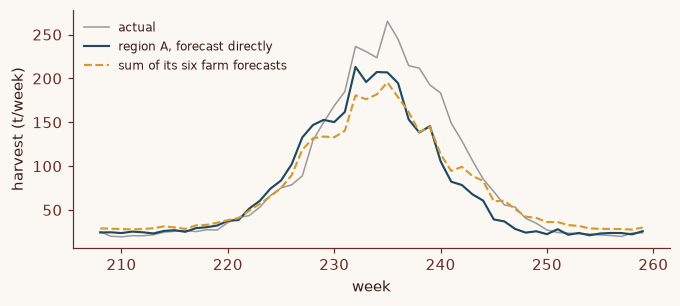

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(origins + H, Y[1, origins + H], color="0.6", lw=1, label="actual")
ax.plot(origins + H, base[1], color=C1, lw=1.4, label="region A, forecast directly")
ax.plot(origins + H, base[3:3 + FARMS].sum(0), color=C2, lw=1.4, ls="--", label="sum of its six farm forecasts")
ax.set(xlabel="week", ylabel="harvest (t/week)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

<strong>Figure 1 | Two forecasts of one region.</strong> Synthetic region A over season 5: the harvest, the region's own 4-week-ahead forecast, and the sum of its six farms' 4-week-ahead forecasts.

## Bottom-up, top-down and middle-out

Every way of making forecasts coherent can be written in one form[^1]: map all $m$ base forecasts to $n$ farm forecasts, then add those up with $S$:

$$\tilde{\mathbf{y}}_h = S\,G\,\hat{\mathbf{y}}_h$$

where $\hat{\mathbf{y}}_h$ is the vector of the 15 base forecasts for horizon $h$ (t/week), $\tilde{\mathbf{y}}_h$ the reconciled forecasts (t/week), and $G$ an $n \times m$ matrix of weights (dimensionless) that is the whole method. Whatever $G$ is, $\tilde{\mathbf{y}}_h$ is coherent, because it is $S$ times something. The three classical methods each keep one level:

- **Bottom-up** keeps the farm forecasts and sums them: $G = [\,0 \mid I\,]$ ignores the first three base forecasts.
- **Top-down** keeps the total forecast and splits it: $G = [\,\mathbf{p} \mid 0\,]$, where $\mathbf{p}$ holds each farm's share of the total over the last 52 weeks (dimensionless, summing to 1). Splitting by the shares of the lower-level *forecasts* instead of history performed best among the top-down variants Athanasopoulos, Ahmed and Hyndman compared on tourism hierarchies[^2].
- **Middle-out** keeps the region forecasts, splits each among its farms by within-region shares, and sums up for the total.

They are not equally safe. If the base forecasts are unbiased, the reconciled ones are guaranteed to be unbiased only if $S\,G\,S = S$. Hand the method forecasts that already add up, and it must return them unchanged. A method that fails the check alters even coherent, unbiased forecasts, and so builds in bias. The paper that introduced this form shows top-down never passes, whatever the proportions; middle-out fails too, because it overwrites the farms with last season's shares.

## Reconciliation as projection

The alternative is to find the 12 farm forecasts whose sums come as close as possible to all 15 base forecasts at once, trusting each according to how accurate it has been. That is a weighted least-squares regression of the base forecasts on $S$, with a closed form:

$$G = \left(S^\top W^{-1} S\right)^{-1} S^\top W^{-1}$$

where $W$ is the $m \times m$ covariance matrix of the base forecasts' errors ((t/week)$^2$), or anything proportional to it; a large variance means a forecast trusted little. This $G$ passes the check for any $W$.

Panagiotelis and colleagues show that OLS reconciliation never increases the squared error summed over all series, for any forecast and any outcome, not just on average; WLS and MinT have the same guarantee in their own distance, which weights the errors by $W^{-1}$[^3]. None guarantees that a single series or level improves, and the same paper notes that for some outcomes MinT fails to improve the plain summed squared error.

The methods differ only in $W$:

- **OLS**, $W = I$: every base forecast trusted equally, although in tonnes the total's errors are far larger than a farm's.
- **WLS with structural scaling**, $W = \operatorname{diag}(S\mathbf{1})$: each series' error variance taken as proportional to the number of farms it sums, 12, 6 or 1.
- **MinT**, $W$ estimated from the base forecasts' past errors, covariances included. Wickramasuriya, Athanasopoulos and Hyndman derived this $G$ as the one that minimises the mean squared error of the coherent forecasts summed over every series, assuming unbiased base forecasts[^4]. A sample covariance of 15 series is noisy, so the correlations are shrunk toward zero:

$$\hat{W} = \lambda\,\operatorname{diag}(\hat{W}_\text{sample}) + (1 - \lambda)\,\hat{W}_\text{sample}$$

where $\hat{W}_\text{sample}$ is the sample covariance of the errors ((t/week)$^2$) and $\lambda \in [0, 1]$ the shrinkage intensity (dimensionless), estimated by Schäfer and Strimmer's formula[^5].

In the code, `resid` is a 15 × $N$ array: for each series, the $N$ in-sample errors (actual minus fitted) of its training rows at $h = 4$. Any pipeline can supply it, from fitted values or past backtest errors at the same horizon. scikit-learn's `LedoitWolf` and `OAS` also shrink a covariance, but toward a scaled identity, which pulls the total's and the farms' variances toward a common value: a reasonable substitute, not the same estimator. Fitting them to residuals divided by their standard deviations, then rescaling, brings the target close to MinT's diagonal.

In [6]:
def gls(W):
    """G = (S' W^-1 S)^-1 S' W^-1: the projection that trusts each base forecast in proportion to W^-1."""
    Wi = np.linalg.inv(W)
    return np.linalg.solve(S.T @ Wi @ S, S.T @ Wi)


def shrink(E):
    """Covariance of the rows of E, correlations shrunk toward zero (Schafer and Strimmer)."""
    N = E.shape[1]
    Z = (E - E.mean(1, keepdims=True)) / E.std(1, ddof=1, keepdims=True)
    w = Z[:, None] * Z[None, :]  # products for every pair of series, every week
    var_r = N / (N - 1) ** 3 * ((w - w.mean(2, keepdims=True)) ** 2).sum(2)  # variance of each correlation
    off = ~np.eye(len(E), dtype=bool)
    lam = min(1, var_r[off].sum() / (np.corrcoef(E)[off] ** 2).sum())  # shrinkage intensity
    return np.cov(E) * np.where(off, 1 - lam, 1), lam


def methods(hist, resid):
    """Every method as a matrix G (12 x 15). hist: farm harvests over the last season."""
    share = hist.sum(1) / hist.sum()  # each farm's share of the total
    region = hist.reshape(REGIONS, FARMS, -1).sum(2)
    within = region / region.sum(1, keepdims=True)  # each farm's share of its region
    zeros = lambda k: np.zeros((n, k))
    return {
        "bottom-up": np.hstack([zeros(3), np.eye(n)]),
        "top-down": np.hstack([share[:, None], zeros(2 + n)]),
        "middle-out": np.hstack([zeros(1), np.kron(np.eye(REGIONS), np.ones((FARMS, 1))) * within.reshape(-1, 1), zeros(n)]),
        "OLS": gls(np.eye(len(S))),
        "WLS": gls(np.diag(S.sum(1))),  # structural scaling: variance proportional to farms summed
        "MinT": gls(shrink(resid)[0]),
    }


G = methods(b[:, TEST - H - P:TEST - H], resid)  # resid: 15 series x in-sample errors at h = 4
assert [np.allclose(S @ g @ S, S) for g in G.values()] == [True, False, False, True, True, True]
print(f"shrinkage intensity at the first refit: {shrink(resid)[1]:.2f}")
pd.DataFrame(G["middle-out"], index=names[3:], columns=names).iloc[:, :4].round(3)  # first 4 of 15 columns

shrinkage intensity at the first refit: 0.23


,total,region A,region B,A1
A1,0.0,0.215,0.000,0.0
A2,0.0,0.234,0.000,0.0
A3,0.0,0.079,0.000,0.0
A4,0.0,0.077,0.000,0.0
A5,0.0,0.306,0.000,0.0
A6,0.0,0.089,0.000,0.0
B1,0.0,0.000,0.309,0.0
B2,0.0,0.000,0.143,0.0
B3,0.0,0.000,0.202,0.0
B4,0.0,0.000,0.058,0.0


The assertion confirms that bottom-up, OLS, WLS and MinT pass $S\,G\,S = S$ and that top-down and middle-out fail. At the first refit $\lambda = 0.23$. The table is middle-out's $G$, first four of its 15 columns: each farm's row holds its share of its region in that region's column, and the total's column and every farm column (A1's shown) are zero, so those base forecasts are ignored.

## What reconciliation buys

The comparison follows [Backtesting properly](../backtesting/backtesting_properly.ipynb): every week of seasons 5 and 6 is a target, forecast from an origin four weeks earlier, and the base models and $W$ are refitted every 13 weeks on targets already observed. Each series' root mean squared error (RMSE) is divided by its base forecasts' RMSE, and the ratios are combined within a level by geometric mean. RMSE, because these forecasts get summed, so they should be means ([Which metric](../which-metric.qmd)), and reconciliation minimises squared error. One panel is two seasons of one history, so the experiment runs on ten independently simulated panels.

In [7]:
def backtest(b, refit_every=13):
    """Rolling origins over seasons 5 and 6: forecast every week H ahead, refit every 13 weeks."""
    Y = S @ b
    fcs, actual = {"base": []}, []
    for start in range(TEST, 6 * P, refit_every):
        origins = np.arange(start, min(start + refit_every, 6 * P)) - H
        base, resid = base_forecasts(Y, start - H, origins)
        fcs["base"].append(base)
        for name, G in methods(b[:, start - H - P:start - H], resid).items():
            fcs.setdefault(name, []).append(S @ G @ base)  # reconciled: coherent by construction
        actual.append(Y[:, origins + H])
    fcs, actual = {k: np.hstack(v) for k, v in fcs.items()}, np.hstack(actual)
    rmse = pd.DataFrame({k: np.sqrt(((f - actual) ** 2).mean(1)) for k, f in fcs.items()}, index=names)
    return rmse.div(rmse["base"], axis=0)  # each series' RMSE relative to its own base forecast


def gmean(x):
    return np.exp(np.log(x).mean())

In [8]:
runs = pd.concat([backtest(simulate(seed)).assign(level=level, seed=seed) for seed in range(10)])
cols = ["bottom-up", "top-down", "middle-out", "OLS", "WLS", "MinT"]
by_level = runs.groupby("level")[cols].agg(gmean).loc[["total", "region", "farm"]]
wins = (runs.groupby(["seed", "level"])[cols].agg(gmean).round(9) < 1).groupby("level").sum()
print("panels (of 10) where the method beat the base forecasts at that level:", wins.loc[by_level.index], sep="\n")
(100 * (by_level - 1)).round(1) + 0.0  # % change in RMSE against the base forecasts; negative is better

panels (of 10) where the method beat the base forecasts at that level:
        bottom-up  top-down  middle-out  OLS  WLS  MinT
level                                                  
total           1         0           4    7    4     5
region          1         3           0    8    8     7
farm            0         5          10    7    9     9


,bottom-up,top-down,middle-out,OLS,WLS,MinT
level,,,,,,
total,22.4,0.0,0.0,-0.8,1.1,-1.1
region,12.3,24.4,0.0,-1.6,-1.7,-2.5
farm,0.0,-2.2,-9.0,-1.3,-2.7,-3.3


The table is the change in RMSE against the base forecasts, in percent; negative is better. Top-down leaves the total unchanged and middle-out the regions. Read first the row for the level you plan at, then check that no other row you rely on got worse.

Bottom-up made the regions $12.3\%$ worse and the total $22.4\%$ worse, beating the base total in 1 panel of 10: summing six farm forecasts adds up six models' chasing of noise the region's own model never saw. Top-down made the regions $24.4\%$ worse; one fixed share of the total cannot follow two regions that peak in different weeks and have different years.

Middle-out gave the best farm forecasts, $9.0\%$ better, in all 10 panels. Region forecasts are good here, and a farm's share of its region is stable apart from the pickers' moves, which a farm's own model only chases. That is a property of this synthetic hierarchy, not a rule; middle-out's farm forecasts are biased whenever shares drift.

OLS and MinT were the only methods better at every level: MinT by $1.1\%$ at the total, $2.5\%$ at the regions and $3.3\%$ at the farms, OLS by $0.8\%$, $1.6\%$ and $1.3\%$. WLS was close to MinT below the total but made the total $1.1\%$ worse. The gains are small and vary: MinT beat the base total in only 5 panels of 10, the regions in 7 and the farms in 9.

**A recipe.**

- Make base forecasts for every series with any model; the previous module's gradient-boosted global model plugs in unchanged.
- Reconcile each horizon separately, with $W$ and $G$ built from that horizon's residuals. This is a practical choice; the MinT paper instead assumes each horizon's covariance is proportional to the one-step one.
- Try MinT with shrinkage first. With little residual history the covariance is hard to estimate: fall back to structural WLS, which needs no residuals, or OLS. In Wickramasuriya and colleagues' simulations, bottom-up also did especially well with small samples.
- Choose by a backtest scored level by level.

Reconciliation moves forecasts toward each other, not toward the truth, so it cannot remove a bias every level shares; Panagiotelis and colleagues found that correcting the base forecasts' bias before reconciling beat reconciling alone. It can also return negative harvests for small farms in quiet weeks, since $G$ has negative weights. A practical fix, not a result from these sources, is to clip the farm forecasts at zero and sum them up again, which restores coherence, though the result is no longer a projection.

## Key takeaways

- Forecasts made independently at each level are incoherent: here a region's forecast and the sum of its farms' differed by $12\%$ of the region's harvest on average.
- Write the hierarchy as $\mathbf{y} = S\mathbf{b}$ and any reconciliation as $\tilde{\mathbf{y}} = S G \hat{\mathbf{y}}$. Bottom-up, top-down and middle-out are fixed choices of $G$; only those with $S G S = S$ keep unbiased forecasts unbiased, and top-down never does.
- OLS, WLS and MinT use every level, $G = (S^\top W^{-1} S)^{-1} S^\top W^{-1}$. OLS never increases the squared error summed over all series; no method guarantees that any one level improves.
- Over ten synthetic panels, OLS and MinT improved RMSE at every level, MinT by $1$–$3\%$; bottom-up made the total $22\%$ worse; middle-out gave the best farms. Start with MinT, fall back to WLS or OLS when residuals are few, and choose from a per-level backtest.

## References

[^1]: Hyndman, R. J., Ahmed, R. A., Athanasopoulos, G. & Shang, H. L. Optimal combination forecasts for hierarchical time series. *Comput. Stat. Data Anal.* **55**, 2579–2589 (2011). https://doi.org/10.1016/j.csda.2011.03.006
[^2]: Athanasopoulos, G., Ahmed, R. A. & Hyndman, R. J. Hierarchical forecasts for Australian domestic tourism. *Int. J. Forecast.* **25**, 146–166 (2009). https://doi.org/10.1016/j.ijforecast.2008.07.004
[^3]: Panagiotelis, A., Athanasopoulos, G., Gamakumara, P. & Hyndman, R. J. Forecast reconciliation: a geometric view with new insights on bias correction. *Int. J. Forecast.* **37**, 343–359 (2021). https://doi.org/10.1016/j.ijforecast.2020.06.004
[^4]: Wickramasuriya, S. L., Athanasopoulos, G. & Hyndman, R. J. Optimal forecast reconciliation for hierarchical and grouped time series through trace minimization. *J. Am. Stat. Assoc.* **114**, 804–819 (2019). https://doi.org/10.1080/01621459.2018.1448825
[^5]: Schäfer, J. & Strimmer, K. A shrinkage approach to large-scale covariance matrix estimation and implications for functional genomics. *Stat. Appl. Genet. Mol. Biol.* **4**, issue 1 (2005). https://doi.org/10.2202/1544-6115.1175

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/conformal-prediction/conformal_prediction.html"><span>Previous</span>Conformal prediction</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/many-series/forecasting_many_series.html"><span>Next</span>Forecasting many series at once</a></div>
<!-- CURRICULUM_FOOTER_END -->